# **MÓDULO 21 - Projeto de Credit Score - Árvore de Decisão**


No módulo 17, vocês realizaram a primeira etapa do projeto de crédito de vocês. Então fizeram o tratamendo dos dados, balancearam as classes, transformaram as variáveis categóricas e separam base de treino e teste. Já no módulo 14, aplicaram a base já tratada o algoritmo de Naive Bayes, onde avaliaram os resultados das previsões. Nesse módulo aplicaremos a nossa base o algoritmo da árvore de decisão.

In [22]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1) Comece carregando as bases de treino (X e y) e teste (X e y).
Verifique se o número de linhas condiz, se as variáveis estão corretas sendo apenas a de score para y e as demais nas bases de X e por último, se Y está balanceada no teste.

In [23]:
# Carregando as bases
x_train = pd.read_csv("X_train_balanced.csv")
x_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train_balanced.csv")
y_test = pd.read_csv("y_test.csv")

In [24]:
# Validando as bases
# Número de linhas
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

# Colunas em X
x_train.columns

# Balanceamento de y_teste
y_test['Credit Score'].value_counts()

(255, 7)
(41, 7)
(255, 1)
(41, 1)


Credit Score
3    28
2     9
1     4
Name: count, dtype: int64

# 2) Explique com suas palavras, qual o passo a passo para a aplicação do algoritmo da árvore de decisão, não esqueça de citar a etapa de avaliação do modelo e também como podemos melhorar nosso modelo.

Para o primeiro momento, é preciso carregar a base de dados. Após isso, realiza-se a fase de pré-processamento, isto é, tratar o dataset, identificar nulos e outliers, separar as bases em treino e teste e realizar o balanceamento das bases. Feito o pré-processamento, no segundo momento as bases previamente salvas devem ser carregadas no projeto referente a árvore de decisão. E finalizando, as bases devem ser verificadas (linhas, variáveis e balanceamento).

Para a árvore de decisão, deverá ser aplicado o algoritmo, e nele, utilizar gini como critério e random state = 0. Após a aplicação do algoritmo, deverão ser obtidas as previsões e acurácia do treino e teste para avaliar a existência de overfitting observando-se a acurácia do treino e teste, se no caso, o treino indica uma acurácia maior que o teste, dando a impressão de que o modelo decorou os dados, e não aprendeu com eles, isso é visível caso a diferença entre treino e teste demonstre uma diferença grande, com uma acurácia muito menor do teste se comparado com o treino. E então será analisado por meio de um relatório de classificação a precisão e o recall dentro das classes 1, 2 e 3. Além dessas métricas, o F1-score ajuda ao avaliar a classificação dos resultados, e a matriz de confusão ajuda a visualizar a distribuição em previsão e dados reais. Caso necessário, será preciso ajustar a profundidade da árvore, e de alguns outros parâmetros para regular e evitar overfitting.

Por fim, deverá ser analisada e visualizada a importância de cada feature dentro do dataset utilizando feature_importances_ e um gráfico de barras para visualizar, então construindo a árvore de decisão em cima das duas features mais importantes do dataset, para que enfim, os resultados entre a árvore com as duas features e a árvore anterior possam ser comparados.

# 3) Aplique o algortimo da árvore de decisão aos dados de treinamento, utilizando critério de Gini e random state = 0.
Traga a acurácia para o modedlo com os dados de treino.

In [25]:
# Declarando a varíavel onde a árvore estará guardada
arvore_credito = DecisionTreeClassifier(criterion = 'gini', random_state=0)

# Realizando o treino
arvore_credito.fit(x_train, y_train)

# Aplicando o modelo
previsoes = arvore_credito.predict(x_train)
acuracia = accuracy_score(y_train, previsoes)
print("Acurácia:", acuracia)

Acurácia: 1.0


# 4) Aplique o modelo aos dados de teste e realize a avaliação dos resultados. Não se esqueça de avaliar com as suas palavras e comparar o desempenho da base treino com a teste.

In [26]:
# Aplicando o modelo
previsoes_teste = arvore_credito.predict(x_test)
acuracia_teste = accuracy_score(y_test, previsoes_teste)
print("Acurácia teste:", acuracia_teste)

Acurácia teste: 0.975609756097561


In [27]:
# Obtendo o relatório de classificação
relatorio = classification_report(y_test, previsoes_teste)
print("Relatório de Classificação:")
print(relatorio)

Relatório de Classificação:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         4
           2       0.90      1.00      0.95         9
           3       1.00      0.96      0.98        28

    accuracy                           0.98        41
   macro avg       0.97      0.99      0.98        41
weighted avg       0.98      0.98      0.98        41



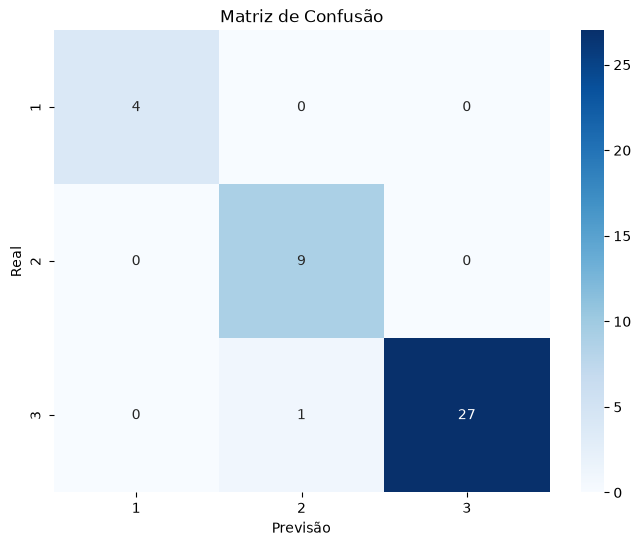

In [28]:
matriz_confusao = confusion_matrix(y_test, previsoes_teste)

# Plotando a matriz de confusão como um mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusao, annot=True, cmap='Blues', fmt='d',
            xticklabels=['1', '2', '3'],
            yticklabels=['1', '2', '3'])
plt.xlabel('Previsão')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.show()

Analisando o desempenho da aplicação do algoritmo, é perceptível que, apesar do treino ter resultado uma acurácia de 100%, o resultado de 97,6% foi satisfatório, pois gerou uma diferença baixa de aproximadamente 2,4 pontos percentuais. Isso indica que o algoritmo aprendeu padrões, abrindo espaço para generalizações ao invés de decorar os dados. Porém, essa conclusão deve ser tomada com cautela, justamente porque cada erro pesa 2,4 pontos de acurácia, e por conta disso, a boa generalização tem pouca folga.

Falando do desempenho do modelo, na matriz de confusão tem um erro. O cliente era classe 3, e o modelo previu classe 2. O modelo classificou 10 clientes como classe 2, mas só 9 eram. Dos 28 clientes realmente classe 3, o modelo acertou 27. A classe 2 inclusive, é a classe com a precisão mais baixa, de 0,90, e o recall mais baixo é a classe 3 com 0,96. Um único erro derruba dois números diferentes no relatório. O cliente pertencia à classe 3 e foi previsto na classe 2. Em resumo, a classe 3 ficou com 1 cliente faltando, enquanto a classe 2 teve 1 cliente previsto que não fazia parte dessa classe. E sobre a classe 1, o recall de 100% dela foi calculado em cima de 4 amostras, isso é uma evidência fraca de que o modelo realmente acerta a classe 1. Eu confiaria na classe 3, pois apenas um erro não derrubaria o recall bruscamente como acontece na classe 1.

# 5) Plote a árvore de decisão.
É possível fazer uma avaliação visual? Qual a profundidade da árvore?

[1 2 3]


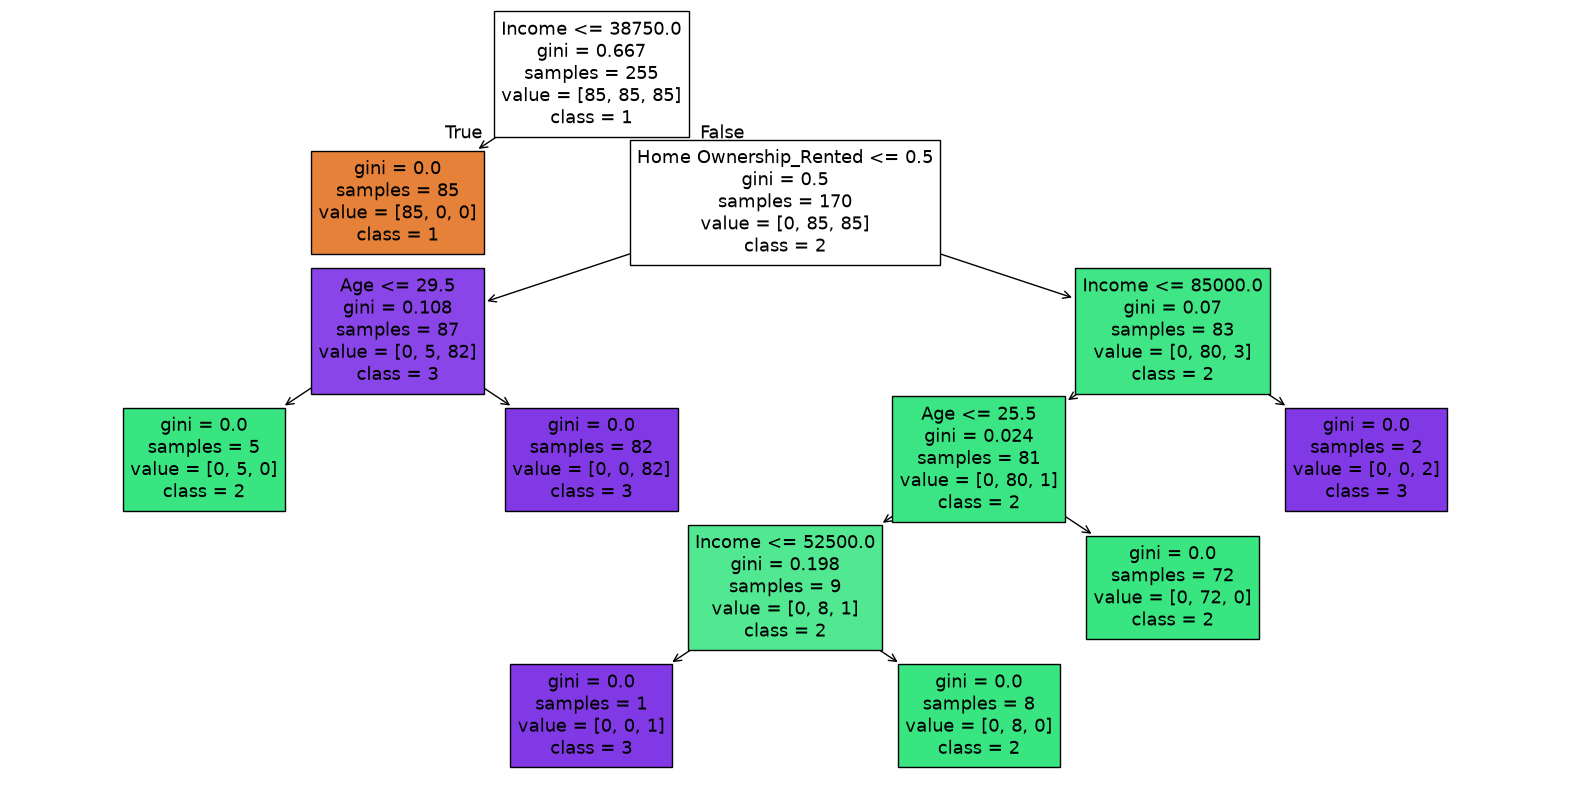

Profundidade da árvore: 5


In [29]:
# Plotando a árvore
plt.style.use('default')
plt.figure(figsize=(20,10), facecolor='white')
plot_tree(arvore_credito, filled=True, feature_names=x_train.columns, class_names=['1','2','3'])
profundidade = arvore_credito.get_depth()
print(arvore_credito.classes_)
plt.show()
print('Profundidade da árvore:', profundidade)

É possível fazer uma avaliação visual: com 255 amostras e três classes bem distintas, a árvore ficou pequena e legível, com profundidade 5. Dá para ler cada nó e seguir o caminho até a classe prevista. Apenas 3 das 7 variáveis foram usadas nos nós de decisão: Income, Age e Home Ownership_Rented.

# 6) Identifique as 2 principais features do modelo.


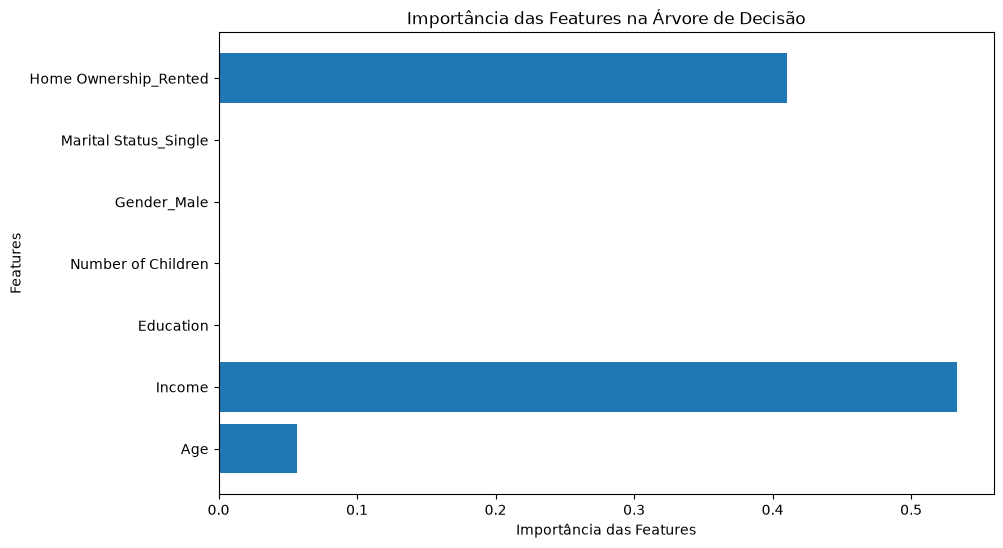

In [30]:
# Obtendo a importância das características do modelo de árvore de decisão
importancias_features = arvore_credito.feature_importances_

# Obtendo os nomes das características
nomes_features = x_train.columns

# Criando um gráfico de barras para visualizar a importância das características
plt.figure(figsize=(10, 6))
plt.barh(nomes_features, importancias_features)
plt.xlabel('Importância das Features')
plt.ylabel('Features')
plt.title('Importância das Features na Árvore de Decisão')
plt.show()

As duas principais features são Income(aproximadamente 0,53) e Home Ownership_Rented(cerca de 0,41). Age apesar de aparecer em dois nós, estes já estavam quase puros, isso faz com que a variável Age pesasse só cerca de 0,06. Isso porque a importância mede o quanto cada variável reduziu o gini da árvore, não quantas vezes ela aparece.

# 7) Rode um modelo de árvore de decisão apenas com as 2 principais features encontradas. E avalie os resultados. Para você o desempenho da árvore está melhor que o modelo anterior? Justifique.

In [31]:
# Reduzindo as bases
x_train_reduzido = x_train[['Home Ownership_Rented', 'Income']]
x_test_reduzido = x_test[['Home Ownership_Rented', 'Income']]

In [32]:
# Criando um novo modelo de árvore a partir das novas bases
arvore_credito_reduzido = DecisionTreeClassifier (criterion = 'gini', random_state = 0)
arvore_credito_reduzido.fit(x_train_reduzido, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [33]:
# Fazendo as previsões a partir da nova árvore
# Treino
previsoes_reduzido_treino = arvore_credito_reduzido.predict(x_train_reduzido)
acuracia_reduzida_treino = accuracy_score(y_train, previsoes_reduzido_treino)
print("Acurácia Reduzida no Treino:", acuracia_reduzida_treino)

# Teste
previsoes_reduzido_teste = arvore_credito_reduzido.predict(x_test_reduzido)
acuracia_reduzida_teste = accuracy_score(y_test, previsoes_reduzido_teste)
print("Acurácia Reduzida no teste:", acuracia_reduzida_teste)

Acurácia Reduzida no Treino: 0.996078431372549
Acurácia Reduzida no teste: 0.9512195121951219


In [34]:
# Novo relatório de classificação
relatorio_reduzido = classification_report(y_test, previsoes_reduzido_teste)
print("Relatório de Classificação Reduzido:")
print(relatorio_reduzido)

Relatório de Classificação Reduzido:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         4
           2       0.89      0.89      0.89         9
           3       0.96      0.96      0.96        28

    accuracy                           0.95        41
   macro avg       0.95      0.95      0.95        41
weighted avg       0.95      0.95      0.95        41



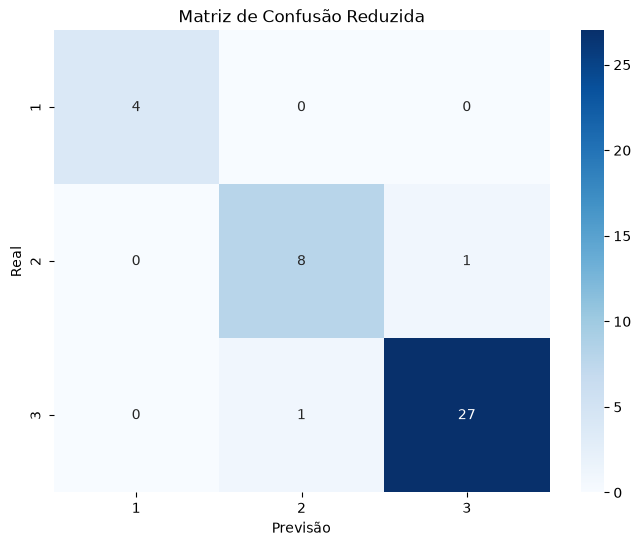

In [35]:
# Nova matriz de confusão
matriz_confusao_reduzida = confusion_matrix(y_test, previsoes_reduzido_teste)

# Plotando a matriz de confusão como um mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusao_reduzida, annot=True, cmap='Blues', fmt='d',
            xticklabels=['1', '2', '3'],
            yticklabels=['1', '2', '3'])
plt.xlabel('Previsão')
plt.ylabel('Real')
plt.title('Matriz de Confusão Reduzida')
plt.show()

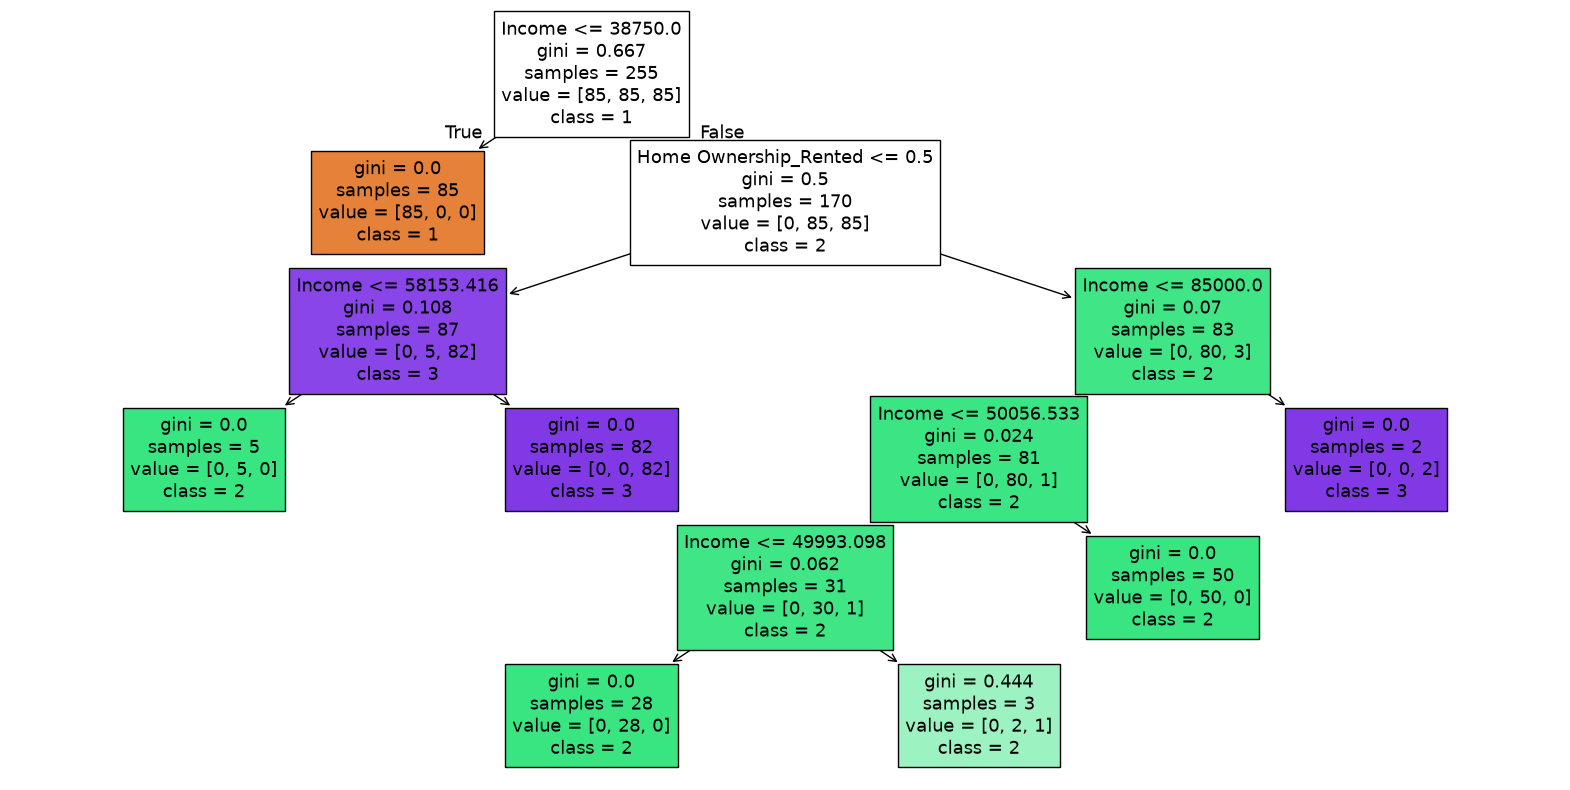

In [36]:
# Plotando a nova árvore
plt.style.use('default')
plt.figure(figsize=(20,10), facecolor='white')
plot_tree(arvore_credito_reduzido, filled=True, feature_names=x_train_reduzido.columns, class_names=['1', '2', '3'])
plt.show()

As acurácias de treino e teste nessa árvore foram diferentes se comparadas com as acurácias da primeira árvore. Em treino, na primeira árvore foi obtida uma acurácia de 100%, enquanto na reduzida foi obtido aproximadamente 99,6%. Em teste, na primeira foi obtido aproximadamente 97,6%, enquanto na reduzida, aproximadamente 95,1%.Analisando as duas árvores, o desempenho ficou ligeiramente pior na versão reduzida, mas a diferença é de uma amostra, então a evidência é fraca. Das 5 variáveis removidas, só a Age tinha importância na árvore, e sem ela o modelo errou 2 amostras no teste, contra 1 na árvore completa. Outro ponto é a folha impura da árvore reduzida (gini 0,444), que explica o treino não chegar a 100%, enquanto na árvore completa todas as folhas são puras.Em contrapartida, o modelo reduzido ficou mais simples. Neste modelo é mais fácil de explicar para algum cliente ou para algum superior que não entende de dados.

# 8) Compare os resultados obtidos com a árvore de decisão com os resultados do Naive Bayes (Exercício módulo 20). Qual parece ter se adequado melhor aos dados e tem melhores resultados de avaliação? Justifique.

Eu escolheria a árvore de decisão. A acurácia de teste empatou (97,6% nos dois modelos). O recall macro favorece a árvore (0,99 contra 0,96), mas essa diferença vem de um único cliente: o erro da árvore caiu na classe 3, de 28 amostras, e o do Naive Bayes na classe 2, de 9, então é um indício fraco. O argumento mais forte é a facilidade de explicar para um cliente o motivo de ter o crédito negado, ilustrando o caminho na árvore, enquanto o Naive Bayes dependeria de explicações baseadas na teoria estatística. Como ressalva, o erro da árvore prejudica o cliente (previu classe 2 para um de classe 3), enquanto o do Naive Bayes expõe a empresa; mas foi um erro em 41 amostras, e a árvore permite auditar onde ele nasceu.